# Python & APIs: A Winning Combo for Reading Public Data by Pedro Pregueiro

#### Table of Contents

* Getting to Know APIs
    * SOAP vs REST vs GraphQL
    * APIs and requests: A Match Made in Heaven
* Calling Your First API Using Python
    * Endpoints and Resources
    * Request and Response
    * Status Codes
    * HTTP Headers
    * Response Content
    * HTTP Methods
    * Query Parameters
* Learning Advanced API Concepts
    * Authentication
    * Pagination
    * Rate Limiting
* Consuming APIs With Python: Practical Examples
    * Searching and Fetching Trending GIFs
    * Searching Google Books
* Conclusion

Python is an excellent choice for working with Application Programming Interfaces (APIs), allowing you to efficiently consume and interact with them. By using the Requests library, you can easily fetch data from APIs that communicate using HTTP, such as REST, SOAP, or GraphQL APIs. This tutorial covers the essentials of consuming REST APIs with Python, including authentication and handling responses.

**By the end of this tutorial**, **you’ll understand that**:

* An **API** is an interface that allows different systems to communicate, typically through requests and responses.

* Python is a versatile language for **consuming APIs**, offering libraries like **Requests** to simplify the process.

* **REST and GraphQL** are two common **types of APIs**, with REST being more widely used for public APIs.

* To handle **API authentication in Python**, you can use API keys or more complex methods like **OAuth** to access protected resources.

Knowing how to consume an API is one of those magical skills that, once mastered, will crack open a whole new world of possibilities, and consuming APIs using Python is a great way to learn such a skill.

By the end of this tutorial, you’ll be able to use Python to consume most of the APIs that you come across. If you’re a developer, then knowing how to consume APIs with Python will empower you to integrate data from various online sources into your applications

## Getting to Know APIs

API stands for **application programming interface**. In essence, an API acts as a communication layer, or interface, that allows different systems to talk to each other without having to understand exactly what the others do.

APIs can come in many forms or shapes. They can be operating system APIs, used for actions like turning on your camera and audio when joining a Zoom call. Or they can be web APIs, used for web-focused actions, such as liking images on your Instagram or fetching the latest tweets.

No matter the type, all APIs function mostly the same way. You usually make a **request** for information or data, and the API returns a **response** with what you requested. For example, every time you open Twitter or scroll down your Instagram feed, you’re basically making a request to the API behind that app and getting a response in return. This is also known as **calling** an API.

In this tutorial, you’ll focus more on the high-level APIs that communicate across networks, also called web APIs.

### SOAP vs REST vs GraphQL

Even though some of the examples above are geared toward newer platforms or apps, web APIs have been around for quite a long time. In the late 1990s and early 2000s, two different design models became the norm in exposing data publicly:
1.   **SOAP (Simple Object Access Protocol)** is typically associated with the enterprise world, has a stricter contract-based usage, and is mostly designed around actions.
2.   **REST (Representational State Transfer)** is typically used for public APIs and is ideal for fetching data from the Web. It’s much lighter and closer to the HTTP specification than SOAP.

Nowadays, there’s a new kid in town: GraphQL. Created by Facebook, GraphQL is a very flexible query language for APIs, where the clients decide exactly what they want to fetch from the server instead of letting the server decide what to send.

Even though **GraphQL** is on the rise and is being adopted by bigger and bigger companies, including [GitHub](https://docs.github.com/en/graphql) and [Shopify](https://shopify.dev/docs/admin-api/graphql/reference), the truth is that the majority of public APIs are still REST APIs. Therefore, for the purpose of this tutorial, you’ll learn only about REST APIs and how to consume them using Python.

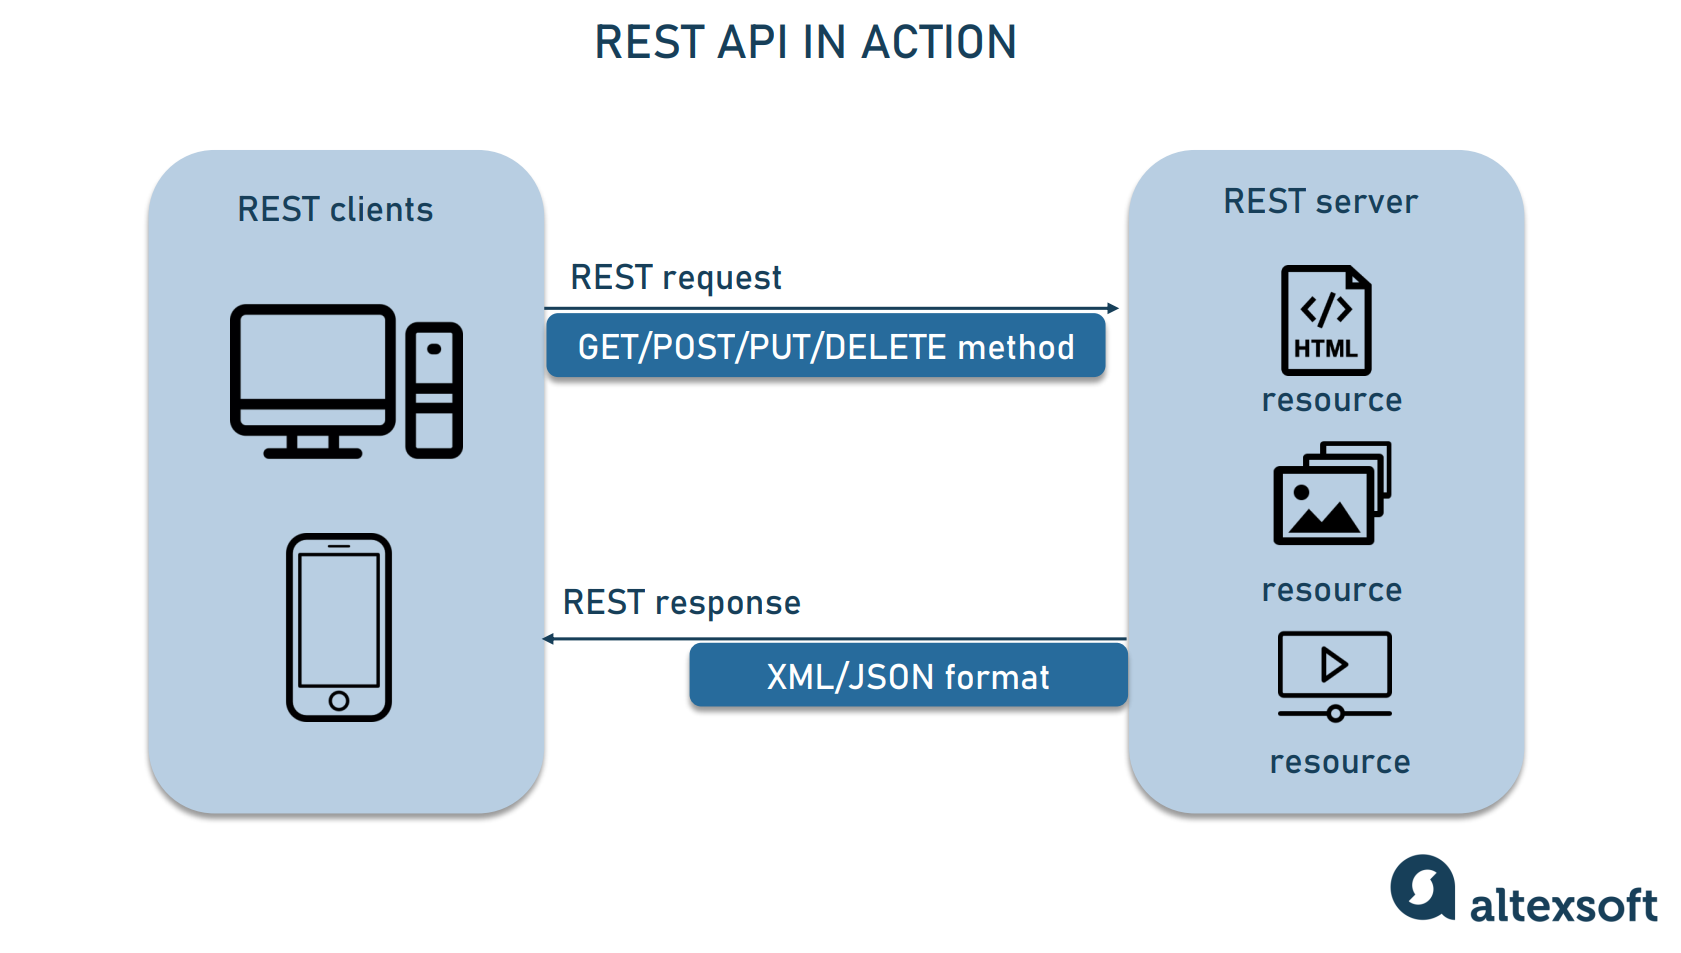

### APIs and `requests`: A Match Made in Heaven

When consuming APIs with Python, there’s only one library you need: [requests](https://requests.readthedocs.io/en/latest/). With it, you should be able to do most, if not all, of the actions required to consume any public API.

You can install `requests` by running the following command in your colab:

In [ ]:
!pip install requests

##Calling Your First API Using Python

Enough talking—it’s time to make your first API call! For the first example, you’ll be calling a popular API for generating random user data.

Throughout the tutorial, you’ll see new APIs introduced in alert blocks like the one below. It’s a convenient way for you to scroll through afterward and quickly spot all the new APIs that you learned about.

* ! **Random User Generator API**: This is a great tool for [generating random user data](https://randomuser.me/). You can use it to generate any number of random users and associated data, and you can also specify gender, nationality, and many other filters that can be really helpful when testing apps or, in this case, APIs.

All you need to start with the Random User Generator API is to know which URL to call it with. For this example, the URL to use is https://randomuser.me/api/, and this is the tiniest API call that you can make:

In [ ]:
import requests
requests.get("https://randomuser.me/api/")

<Response [200]>

In this small example, you import the `requests` library and then fetch, or get, data from the URL for the Random User Generator API. But you don’t actually see any of the data returned. What you get instead is a Response `[200]`, which in API terms means everything went okay.

If you want to see the actual data, then you can use `.text` from the returned `Response` object:

In [ ]:
import requests
response = requests.get("https://randomuser.me/api/")
response.text

'{"results":[{"gender":"female","name":{"title":"Mrs","first":"Mariele","last":"Schiller"},"location":{"street":{"number":2701,"name":"Erlenweg"},"city":"Ludwigslust","state":"Hamburg","country":"Germany","postcode":60553,"coordinates":{"latitude":"-53.8586","longitude":"149.4665"},"timezone":{"offset":"+10:00","description":"Eastern Australia, Guam, Vladivostok"}},"email":"mariele.schiller@example.com","login":{"uuid":"ac7f4485-8db5-4915-acf3-b847dfe5e0aa","username":"bluepanda570","password":"westwood","salt":"1UtLgu3V","md5":"382d677ebe8072443aef3216d36b32b7","sha1":"155a8163e4cfd01f806f019b2714bd5bc6b90945","sha256":"c79e94839687c64dacabd9f5d245c777b124f69ccbcf6992b970f24adff2b4ac"},"dob":{"date":"1961-04-11T07:54:04.299Z","age":63},"registered":{"date":"2011-03-05T03:08:52.648Z","age":13},"phone":"0983-8066682","cell":"0177-8925041","id":{"name":"SVNR","value":"29 110461 S 890"},"picture":{"large":"https://randomuser.me/api/portraits/women/79.jpg","medium":"https://randomuser.me/a

That’s it! Now you know the absolute basics of API consumption. You managed to fetch your first random user from the Random User Generator API using Python and the `requests` library.

###Endpoints and Resources

As you saw above, the first piece of information necessary for consuming an API is the API URL, typically called the **base URL**. The base URL structure is no different from the URLs that you use for browsing Google, YouTube, or Facebook, though it usually contains the word `api`. This isn’t mandatory, just more of a rule of thumb.

For example, here are the base URLs for a few well-known API players:

*    https://api.twitter.com
*    https://api.github.com
*    https://api.stripe.com

As you can see, all of the above start with `https://api` and include the remaining official domain, such as `.twitter.com` or `.github.com`. There’s no specific standard for how the API base URL should look, but it’s quite common for it to mimic this structure.

If you try opening any of the above links, then you’ll notice that most of them will return an error or ask for credentials. That’s because APIs sometimes require authentication steps before you can use them. You’ll learn more about this a bit later in the tutorial.

* ! **The Cat API**: This API is quite fun but also a really good example of a well-done API with great [documentation](https://thecatapi.com/). With it, you can fetch the different cat breeds and some images, but if you register, you can also cast votes on your favorite cats.

Next, using the Cat API, you’ll try to make a basic request to see how it may differ from the Random User Generator API that you tried above:

In [ ]:
import requests
response = requests.get("https://api.thecatapi.com/")
response.text

'{"message":"The Cat API","version":"1.3.9"}'

In this case, when calling the base URL, you get this generic message saying `"The Cat API"`. This is because you’re calling the base URL, which is typically used for very basic information about an API, not the real data.

Calling the base URL alone isn’t a lot of fun, but that’s where endpoints come in handy. An **endpoint** is a part of the URL that specifies what **resource** you want to fetch. Well-documented APIs usually contain an **API reference**, which is extremely useful for knowing exactly which endpoints and resources an API has and how to use them.

You can check the [official documentation](https://developers.thecatapi.com/view-account/ylX4blBYT9FaoVd6OhvR?report=bOoHBz-8t) to learn more about how to use the Cat API and what endpoints are available. In there, you’ll find a [/breeds endpoint](https://developers.thecatapi.com/view-account/ylX4blBYT9FaoVd6OhvR?report=bOoHBz-8t) that you can use to fetch all the available breed resources or objects.

Now, give it a try in code locally using the [breeds endpoint](https://developers.thecatapi.com/view-account/ylX4blBYT9FaoVd6OhvR?report=gpN-ReBkp) and some of the API knowledge that you already have:

In [ ]:
response = requests.get("https://api.thecatapi.com/v1/breeds")
response.text

'[{"weight":{"imperial":"7  -  10","metric":"3 - 5"},"id":"abys","name":"Abyssinian","cfa_url":"http://cfa.org/Breeds/BreedsAB/Abyssinian.aspx","vetstreet_url":"http://www.vetstreet.com/cats/abyssinian","vcahospitals_url":"https://vcahospitals.com/know-your-pet/cat-breeds/abyssinian","temperament":"Active, Energetic, Independent, Intelligent, Gentle","origin":"Egypt","country_codes":"EG","country_code":"EG","description":"The Abyssinian is easy to care for, and a joy to have in your home. They’re affectionate cats and love both people and other animals.","life_span":"14 - 15","indoor":0,"lap":1,"alt_names":"","adaptability":5,"affection_level":5,"child_friendly":3,"dog_friendly":4,"energy_level":5,"grooming":1,"health_issues":2,"intelligence":5,"shedding_level":2,"social_needs":5,"stranger_friendly":5,"vocalisation":1,"experimental":0,"hairless":0,"natural":1,"rare":0,"rex":0,"suppressed_tail":0,"short_legs":0,"wikipedia_url":"https://en.wikipedia.org/wiki/Abyssinian_(cat)","hypoallerg

In [ ]:
import pprint
pprint.pprint(response.text)

There you go, your first breed listing using the Cat API!

If you’re a dog person, don’t fret. There’s an API for you, too, with the same endpoint but a different base URL:

In [ ]:
response = requests.get("https://api.thedogapi.com/v1/breeds")
response.text

I bet you’re already thinking about different ways that you can use these APIs to make some cute side project, and that’s the great thing about APIs. Once you start using them, there’s nothing stopping you from turning a hobby or passion into a fun project.

Before you move forward, one thing you need to know about endpoints is the difference between `http://` and `https://`. In a nutshell, HTTPS is the encrypted version of HTTP, making all traffic between the client and the server much safer. When consuming public APIs, you should definitely stay away from sending any private or sensitive information to `http://` endpoints and use only those APIs that provide a secure `https://` base URL.

In the next section, you’ll dig a bit further into the main components of an API call.

###Request and Response

As you very briefly read above, all interactions between a client—in this case, your Python console—and an API are split into a request and a response:

* **Requests** contain relevant data regarding your API request call, such as the base URL, the endpoint, the method used, the headers, and so on.
* **Responses** contain relevant data returned by the server, including the data or content, the status code, and the headers.

Using the Cat API again, you can drill down a bit more into what exactly is inside the Request and Response objects:

In [ ]:
response = requests.get("https://api.thecatapi.com/v1/breeds")
response

<Response [200]>

In [ ]:
response.status_code

200

In [ ]:
response.text

'[{"weight":{"imperial":"7  -  10","metric":"3 - 5"},"id":"abys","name":"Abyssinian","cfa_url":"http://cfa.org/Breeds/BreedsAB/Abyssinian.aspx","vetstreet_url":"http://www.vetstreet.com/cats/abyssinian","vcahospitals_url":"https://vcahospitals.com/know-your-pet/cat-breeds/abyssinian","temperament":"Active, Energetic, Independent, Intelligent, Gentle","origin":"Egypt","country_codes":"EG","country_code":"EG","description":"The Abyssinian is easy to care for, and a joy to have in your home. They’re affectionate cats and love both people and other animals.","life_span":"14 - 15","indoor":0,"lap":1,"alt_names":"","adaptability":5,"affection_level":5,"child_friendly":3,"dog_friendly":4,"energy_level":5,"grooming":1,"health_issues":2,"intelligence":5,"shedding_level":2,"social_needs":5,"stranger_friendly":5,"vocalisation":1,"experimental":0,"hairless":0,"natural":1,"rare":0,"rex":0,"suppressed_tail":0,"short_legs":0,"wikipedia_url":"https://en.wikipedia.org/wiki/Abyssinian_(cat)","hypoallerg

In [ ]:
response.headers

{'x-dns-prefetch-control': 'off', 'x-frame-options': 'SAMEORIGIN', 'strict-transport-security': 'max-age=15552000; includeSubDomains', 'x-download-options': 'noopen', 'x-content-type-options': 'nosniff', 'x-xss-protection': '1; mode=block', 'vary': 'Origin', 'pagination-count': '67', 'pagination-page': '0', 'pagination-limit': '1000', 'access-control-expose-headers': 'Pagination-Count, Pagination-Page, Pagination-Limit', 'content-type': 'application/json; charset=utf-8', 'x-response-time': '1ms', 'X-Cloud-Trace-Context': '855ea463cef07b2ad560a5e203308ea5', 'Date': 'Thu, 27 Feb 2025 13:50:52 GMT', 'Server': 'Google Frontend', 'Content-Length': '76734'}

In [ ]:
response.request

<PreparedRequest [GET]>

In [ ]:
request = response.request
request.url

'https://api.thecatapi.com/v1/breeds'

In [ ]:
request.path_url

'/v1/breeds'

In [ ]:
request.method

'GET'

In [ ]:
request.headers

{'User-Agent': 'python-requests/2.32.3', 'Accept-Encoding': 'gzip, deflate, zstd', 'Accept': '*/*', 'Connection': 'keep-alive'}

Here, you’ve accessed a few of the most important attributes that are available for `Request` and `Response` objects.

You’ll learn more about some of these attributes in this tutorial, but if you want to dig even further, then you can check Mozilla’s documentation on [HTTP messages](https://developer.mozilla.org/en-US/docs/Web/HTTP/Messages) for a more in-depth explanation of each attribute.

###Status Codes

[Status codes](https://developer.mozilla.org/en-US/docs/Web/HTTP/Status) are one of the most important pieces of information to look for in any API response. They tell you if your request was successful, if it’s missing data, if it’s missing credentials, and so on.

With time, you’ll recognize the different status codes without help. But for now, here’s a list with some of the most common status codes that you’ll find:

|Status|code|Description|
|------|----|-----------|
|`200`|`OK`|Your request was successful!
|`201`|`Created`|Your request was accepted, and the resource was created.
|`400`|`Bad Request`|Your request is either wrong or missing some information.
|`401`|`Unauthorized`|Your request requires some additional permissions.
|`404`|`Not Found`|The requested resource doesn’t exist.
|`405`|`Method Not Allowed`|The endpoint doesn’t allow for that specific HTTP method.
|`500`| `Internal Server Error`| 	Your request wasn’t expected and probably broke something on the server side.


You saw `200` `OK` earlier in the examples that you executed, and you might even recognize `404` `Not Found` from browsing the Web.

You can check the status of a response using `.status_code` and `.reason`. The `requests` library also prints the status code in the representation of the `Response` object:

In [ ]:
response = requests.get("https://api.thecatapi.com/v1/breeds")

In [ ]:
response

<Response [200]>

In [ ]:
response.status_code

200

In [ ]:
response.reason

'OK'

Your request returns `200`, so you can consider it a successful request. But now have a look at a failing request triggered when you include a typo in the endpoint:

In [ ]:
response = requests.get("https://api.thecatapi.com/v1/breedz")
response

<Response [404]>

In [ ]:
response.status_code

404

In [ ]:
response.reason

'Not Found'

As you can see, the `/breedz` endpoint doesn’t exist, so the API returns a `404` `Not Found` status code.

You can use these status codes to quickly see if you need to change your request or check the documentation again for any typos or missing pieces.

###HTTP Headers

HTTP headers can define a few parameters governing requests and responses:

|HTTP Header| 	Description|
|-----------|--------------|
|`Accept`| 	What type of content the client can accept
|`Content-Type`| 	What type of content the server will respond with
|`User-Agent`| 	What software the client is using to communicate with the server
|`Server`| 	What software the server is using to communicate with the client
|`Authentication`| 	Who’s calling the API and what credentials they have

There are many other headers that you can find when inspecting a request or response. Have a look at [Mozilla’s extended list](https://developer.mozilla.org/en-US/docs/Web/HTTP/Headers) if you’re curious about the specific use for each of them.

To inspect the headers of a response, you can use `response.headers`:

In [ ]:
response = requests.get("https://api.thecatapi.com/v1/breeds/abys")
response.headers

{'x-dns-prefetch-control': 'off', 'x-frame-options': 'SAMEORIGIN', 'strict-transport-security': 'max-age=15552000; includeSubDomains', 'x-download-options': 'noopen', 'x-content-type-options': 'nosniff', 'x-xss-protection': '1; mode=block', 'vary': 'Origin', 'content-type': 'application/json; charset=utf-8', 'x-response-time': '1ms', 'X-Cloud-Trace-Context': '0730b1ddbb1c007fce4efcf7773356c9', 'Date': 'Thu, 27 Feb 2025 14:08:06 GMT', 'Server': 'Google Frontend', 'Content-Length': '1041'}

To do the same with the request headers, you can use response`.request.headers` since `request` is an attribute of the `Response` object:

In [ ]:
response = requests.get("https://api.thecatapi.com/v1/breeds/abys")
response.request.headers

{'User-Agent': 'python-requests/2.32.3', 'Accept-Encoding': 'gzip, deflate, zstd', 'Accept': '*/*', 'Connection': 'keep-alive'}

In this case, you don’t define any specific headers when you make the request, so Python returns the default headers.

####Custom Headers

Another standard that you might come across when consuming APIs is the use of custom headers. These usually start with `X-`, but that’s not a requirement. API developers typically use custom headers to send or request additional custom information from clients.

You can use a dictionary to define headers, and you can send them along with your request using the headers parameter of `.get()`.

For example, say you want to send some request ID to the API server, and you know you can do that using `X-Request-Id`:

In [ ]:
headers = {"X-Request-Id": "<my-request-id>"}
response = requests.get("https://example.org", headers=headers)
response.request.headers


{'User-Agent': 'python-requests/2.32.3', 'Accept-Encoding': 'gzip, deflate, zstd', 'Accept': '*/*', 'Connection': 'keep-alive', 'X-Request-Id': '<my-request-id>'}

If you go through the request.headers dictionary, then you’ll find `X-Request-Id` right at the end, among a few other headers that come by default with any API request.

A response might have many useful types of headers, but one of the most important ones is `Content-Type`, which defines the kind of content returned in the response.

####Content-Type

These days, most APIs use JSON as the default content type, but you might need to use an API that returns XML or other media types, such as images or video. In that case, the content type will differ.

If you look back to one of the previous examples using the Cat API and try to inspect the `Content-Type` header, then you’ll notice how it was defined as `application/json`:

In [ ]:
response = requests.get("https://api.thecatapi.com/v1/breeds/abys")
response.headers.get("Content-Type")

'application/json; charset=utf-8'

The header returns the specific type of content, which is `application/json` in this case. It might also return the specified encoding for the response content.

* ! **Image-Charts API**: This is a useful API that you can use to create [charts](https://www.image-charts.com/) in different sizes that you can use on your website.

If, for example, you try to fetch a chart from the [Image-Charts API](https://documentation.image-charts.com/), then you’ll notice that the content type is no longer application/json, but instead it’s defined as `image/png`:

In [ ]:
url = "https://image-charts.com/chart?chs=700x125&cht=ls&chd=t:23,15,28"
response = requests.get(url)
response


<Response [200]>

In [ ]:
response.headers.get("Content-Type")

'image/png'

In this case, the `Content-Type` header states that the returned content is a PNG image. You’ll learn how to view this content in the next section.

The `Content-Type` header is very important for you to know how to handle a response and what to do with its content. There are [hundreds](http://www.iana.org/assignments/media-types/media-types.xhtml) of other acceptable content types, including audio, video, fonts, and more.

###Response Content

As you just learned, the type of content you find in the API response will vary according to the `Content-Type` header. To properly read the response contents according to the different `Content-Type` headers, the `requests` package comes with a couple of different Response attributes that you can use to manipulate the response data:

* **.text** returns the response contents in Unicode format.
* **.content** returns the response contents in bytes.

You already used the `.text` attribute above. But for some specific types of data, like images and other nontextual data, using `.content` is typically a better approach, even if it returns a very similar result to `.text`:

In [ ]:
response = requests.get("https://api.thecatapi.com/v1/breeds/abys")
response.headers.get("Content-Type")

'application/json; charset=utf-8'

In [ ]:
response.content

b'{"weight":{"imperial":"7  -  10","metric":"3 - 5"},"id":"abys","name":"Abyssinian","cfa_url":"http://cfa.org/Breeds/BreedsAB/Abyssinian.aspx","vetstreet_url":"http://www.vetstreet.com/cats/abyssinian","vcahospitals_url":"https://vcahospitals.com/know-your-pet/cat-breeds/abyssinian","temperament":"Active, Energetic, Independent, Intelligent, Gentle","origin":"Egypt","country_codes":"EG","country_code":"EG","description":"The Abyssinian is easy to care for, and a joy to have in your home. They\xe2\x80\x99re affectionate cats and love both people and other animals.","life_span":"14 - 15","indoor":0,"lap":1,"alt_names":"","adaptability":5,"affection_level":5,"child_friendly":3,"dog_friendly":4,"energy_level":5,"grooming":1,"health_issues":2,"intelligence":5,"shedding_level":2,"social_needs":5,"stranger_friendly":5,"vocalisation":1,"experimental":0,"hairless":0,"natural":1,"rare":0,"rex":0,"suppressed_tail":0,"short_legs":0,"wikipedia_url":"https://en.wikipedia.org/wiki/Abyssinian_(cat)",

As you can see, there isn’t a big difference between `.content` and the previously used `.text`, although the `b` indicates that the returned value consists of raw bytes instead of a string.

By looking at the response’s `Content-Type` header, you can see that the content is `application/json`, a JSON object. For that kind of content, the `requests` library includes a specific `.json()` method that you can use to immediately convert the API bytes response into a Python data structure:

In [ ]:
response = requests.get("https://api.thecatapi.com/v1/breeds/abys")
response.headers.get("Content-Type")

'application/json; charset=utf-8'

In [ ]:
response.json()

{'weight': {'imperial': '7  -  10', 'metric': '3 - 5'},
 'id': 'abys',
 'name': 'Abyssinian',
 'cfa_url': 'http://cfa.org/Breeds/BreedsAB/Abyssinian.aspx',
 'vetstreet_url': 'http://www.vetstreet.com/cats/abyssinian',
 'vcahospitals_url': 'https://vcahospitals.com/know-your-pet/cat-breeds/abyssinian',
 'temperament': 'Active, Energetic, Independent, Intelligent, Gentle',
 'origin': 'Egypt',
 'country_codes': 'EG',
 'country_code': 'EG',
 'description': 'The Abyssinian is easy to care for, and a joy to have in your home. They’re affectionate cats and love both people and other animals.',
 'life_span': '14 - 15',
 'indoor': 0,
 'lap': 1,
 'alt_names': '',
 'adaptability': 5,
 'affection_level': 5,
 'child_friendly': 3,
 'dog_friendly': 4,
 'energy_level': 5,
 'grooming': 1,
 'health_issues': 2,
 'intelligence': 5,
 'shedding_level': 2,
 'social_needs': 5,
 'stranger_friendly': 5,
 'vocalisation': 1,
 'experimental': 0,
 'hairless': 0,
 'natural': 1,
 'rare': 0,
 'rex': 0,
 'suppressed_ta

In [ ]:
response.json()["name"]

'Abyssinian'

As you can see, after executing `response.json()`, you get a dictionary that you’re able to use as you’d use any other dictionary in Python.

Now, looking back at the recent example that you ran using the Image-Charts API, try to fetch that same line chart and have a look at its content:


In [ ]:
url = "https://image-charts.com/chart?chs=700x125&cht=ls&chd=t:23,15,28"
response = requests.get(url)
response

<Response [200]>

In [ ]:
response.headers.get("Content-Type")

'image/png'

In [ ]:
response.content

In this case, because you’re requesting an image, `.content` isn’t very helpful. In fact, it’s nearly impossible to understand. However, you know this is a PNG image, so you can try storing it in a file and see what happens:

In [ ]:
with open("chart.png", mode="wb") as file:
        file.write(response.content)

Now if you open the folder you’re working from, then you’ll find a `chart.png` file, which is an image of the line chart that you just fetched using an API. Isn’t that amazing?

###HTTP Methods

When calling an API, there are a few different methods, also called **verbs**, that you can use to specify what action you want to execute. For example, if you wanted to fetch some data, then you’d use the method `GET`, and if you wanted to create some data, then you’d use the method `POST`.

When purely consuming data using APIs, you’ll typically stick to GET requests, but here’s a list of the most common methods and their typical use case:

|HTTP Method 	|Description 	|Requests method|
|---------------|---------------|---------------|
|`POST` 	|Create a new resource. 	|`requests.post()`
|`GET` 	|Read an existing resource. 	|`requests.get()`
|`PUT` 	|Update an existing resource. 	|`requests.put()`
|`DELETE` 	|Delete an existing resource. 	|`requests.delete()`

You’ll typically refer to these four methods as **CRUD operations** because they allow you to create, read, update and delete resources.

* ! **Note**: There’s an additional `PATCH` method that’s also associated with CRUD operations, but it’s slightly less common than the four above. It’s used to make partial modifications instead of completely replacing a resource using `PUT`.

You can read a bit more about the differences between PUT and PATCH to understand their different needs.

If you’re curious about the remaining HTTP methods, or if you just want to learn a bit more about those you’ve already discovered, then have a look through [Mozilla’s documentation](https://developer.mozilla.org/en-US/docs/Web/HTTP/Methods).

Until now, you’ve only used `.get()` to fetch data, but you can use the requests package for all the other HTTP methods as well:

In [ ]:
requests.post("https://api.thecatapi.com/v1/breeds/abys")

<Response [405]>

In [ ]:
requests.get("https://api.thecatapi.com/v1/breeds/abys")

<Response [200]>

In [ ]:
requests.put("https://api.thecatapi.com/v1/breeds/abys")

<Response [405]>

In [ ]:
requests.delete("https://api.thecatapi.com/v1/breeds/abys")

<Response [405]>

If you try these on your console, then you’ll notice that most of them will return a `405 Method Not Allowed` status code. That’s because not all endpoints will allow for `POST`, `PUT`, or `DELETE` methods. Especially when you’re reading data using public APIs, you’ll find that most APIs will only allow `GET` requests since you’re not allowed to create or change the existing data.

###Query Parameters

Sometimes when you call an API, you get a ton of data that you don’t need or want. For example, when calling the Cat API’s `/breeds` endpoint, you get a lot of information about a given breed. But in some cases, you might want to extract only certain information about a given breed. That’s where query parameters come in!

You might have seen or used query parameters when browsing online. For example, when watching a YouTube video, you have a URL like https://www.youtube.com/watch?v=aL5GK2LVMWI. The `v=` in the URL is what you call a **query parameter**. It typically comes after the base URL and endpoint.

To add a query parameter to a given URL, you have to add a question mark `(?)` before the first query parameter. If you want to have multiple query parameters in your request, then you can split them with an ampersand `(&)`.

The same YouTube URL above with multiple query parameters would look like this: https://www.youtube.com/watch?v=aL5GK2LVMWI&t=75.

* ! **Note**: If you look closely at the URL that you used to call the Image-Charts API earlier, then you’ll note that it contains several query parameters as well.

In the API world, query parameters are filters that you can send with your API request to further narrow down the responses. For example, going back to the Random User Generator API, you know how to generate a random user:

In [ ]:
requests.get("https://randomuser.me/api/").json()

{'results': [{'gender': 'female',
   'name': {'title': 'Mrs', 'first': 'Ceyhan', 'last': 'Kunt'},
   'location': {'street': {'number': 7982, 'name': 'Atatürk Sk'},
    'city': 'Karabük',
    'state': 'Gaziantep',
    'country': 'Turkey',
    'postcode': 75833,
    'coordinates': {'latitude': '65.3385', 'longitude': '167.3666'},
    'timezone': {'offset': '-9:00', 'description': 'Alaska'}},
   'email': 'ceyhan.kunt@example.com',
   'login': {'uuid': '3981c0f5-b003-4d49-8fc8-d923f4975c14',
    'username': 'orangesnake654',
    'password': 'sander',
    'salt': 'bdm3rIb7',
    'md5': '799ec9d523a1dc3b5df310c03eedf783',
    'sha1': '6ad8ffb7a4a07749b12103e6aae888eb9422e12b',
    'sha256': 'b7a07ff444d6a975d81f495659efba289daca631c568da22754f9e5068f718b8'},
   'dob': {'date': '1953-01-26T03:23:42.942Z', 'age': 72},
   'registered': {'date': '2007-01-19T14:45:23.904Z', 'age': 18},
   'phone': '(254)-370-2370',
   'cell': '(639)-437-8081',
   'id': {'name': '', 'value': None},
   'picture': {

However, let’s say you specifically want to generate only random female users. According to the [documentation](https://randomuser.me/documentation#gender), you can use the query parameter `gender=` for that:

In [ ]:
requests.get("https://randomuser.me/api/?gender=female").json()

{'results': [{'gender': 'female',
   'name': {'title': 'Mrs', 'first': 'Yasemin', 'last': 'Çörekçi'},
   'location': {'street': {'number': 8760, 'name': 'Doktorlar Cd'},
    'city': 'Batman',
    'state': 'Diyarbakır',
    'country': 'Turkey',
    'postcode': 98721,
    'coordinates': {'latitude': '71.5884', 'longitude': '176.6609'},
    'timezone': {'offset': '-11:00', 'description': 'Midway Island, Samoa'}},
   'email': 'yasemin.corekci@example.com',
   'login': {'uuid': 'e91e2e4f-c915-477f-81c2-72c5f8a036f5',
    'username': 'smalldog501',
    'password': 'annmarie',
    'salt': 'XJdtEC0c',
    'md5': '32f33528207a3cac29282d46dbe5eeb8',
    'sha1': 'd0d46746cc589b507bf58ed60259d30ba541eea4',
    'sha256': '11c2b828daccfa1bfbfc09f16786b7ec29bb24a7e4b80697a3a148f89923c0e6'},
   'dob': {'date': '1954-06-03T07:40:59.020Z', 'age': 70},
   'registered': {'date': '2017-06-02T04:40:34.588Z', 'age': 7},
   'phone': '(956)-023-9322',
   'cell': '(989)-853-4256',
   'id': {'name': '', 'value':

That’s great! Now say you want to generate only female users from Germany. Again, looking through the documentation, you find a section on [nationality](https://randomuser.me/documentation#nationalities), and you can use the query parameter `nat=` for that:

In [ ]:
requests.get("https://randomuser.me/api/?gender=female&nat=de").json()

{'results': [{'gender': 'female',
   'name': {'title': 'Mrs', 'first': 'Katrin', 'last': 'Kern'},
   'location': {'street': {'number': 9603, 'name': 'Römerstraße'},
    'city': 'Bad Tennstedt',
    'state': 'Nordrhein-Westfalen',
    'country': 'Germany',
    'postcode': 90593,
    'coordinates': {'latitude': '-64.0898', 'longitude': '17.3361'},
    'timezone': {'offset': '-4:00',
     'description': 'Atlantic Time (Canada), Caracas, La Paz'}},
   'email': 'katrin.kern@example.com',
   'login': {'uuid': '694fd19e-9ff2-4b88-99fd-b73e9303af1d',
    'username': 'yellowsnake734',
    'password': 'mooney',
    'salt': 'K77jTIGw',
    'md5': 'e79fbad7e8db067576c59e5e608c575e',
    'sha1': '11f26f2975492977cd2854f8d30bf156ebbba88a',
    'sha256': '28ead9509fd4e0256ba9bf96be445b0fc87bb67c6e8bc0fc393c561d7f733f0c'},
   'dob': {'date': '1970-08-17T12:45:28.064Z', 'age': 54},
   'registered': {'date': '2006-11-01T11:38:51.340Z', 'age': 18},
   'phone': '0520-2690870',
   'cell': '0175-7795501',
 

Using query parameters, you can start fetching more specific data from an API, making the whole experience a bit more tailored to your needs.

To avoid having to rebuild the URL over and over again, you can use the params attribute to send in a dictionary of all the query parameters to append to a URL:

In [ ]:
query_params = {"gender": "female", "nat": "de"}
requests.get("https://randomuser.me/api/", params=query_params).json()

You can apply the above to any other API you like. If you go back to the Cat API, you can return only the breeds that match a specific name. For example, if you wanted to look for the [Ragamuffin breed](https://en.wikipedia.org/wiki/Ragamuffin_cat), then you could do that with the query parameter q=:

In [ ]:
query_params = {"q": "ragamuffin"}
endpoint = "https://api.thecatapi.com/v1/breeds/search"
requests.get(endpoint, params=query_params).json()

There you have it! By sending the query parameter `q=` with the value `ragamuffin`, you’re able to filter all breeds that match that specific value.

* ! **Tip**: When you’re reusing the same endpoint, it’s a best practice to define it as a variable at the top of your code. This will make your life easier when interacting with an API over and over again.

With the help of query parameters, you’re able to further narrow your requests and specify exactly what you’re looking for. Most APIs that you’ll find online will have some sort of query parameters that you can use to filter data. Remember to look through the documentation and API reference to find them.

##Learning Advanced API Concepts

Now that you have a good understanding of the basics of API consumption using Python, there are a few more advanced topics that are worth touching upon, even if briefly, such as authentication, pagination, and rate limiting.

###Authentication

API authentication is perhaps the most complex topic that you’ll explore in this tutorial. Even though a lot of public APIs are free and completely public, even more APIs are available behind some form of authentication. Numerous APIs require authentication, but here are a few good examples:

* [GitHub API](https://docs.github.com/en/rest?apiVersion=2022-11-28)
* [Twitter API](https://docs.x.com/home)
* [Instagram API](https://developers.facebook.com/docs/instagram-platform)

Authentication approaches range from the simplistic and straightforward, like those using API keys or Basic Authentication, to much more complex and safer techniques, like OAuth.

Typically, calling an API without credentials or with the wrong ones will return a 401 Unauthorized or 403 Forbidden status code.

###API Keys

The most common level of authentication is the **API key**. These keys are used to identify you as an API user or customer and to trace your use of the API. API keys are typically sent as a request header or as a query parameter.

* ! **NASA APIs**: One of the coolest collections of publicly available APIs is the one provided by [NASA](https://api.nasa.gov/). You can find APIs to fetch the [astronomy picture of the day](https://apod.nasa.gov/apod/astropix.html) or pictures taken by the Earth Polychromatic Imaging Camera (EPIC) [link text](https://epic.gsfc.nasa.gov/), among others.

For this example, you’ll have a go at NASA’s [Mars Rover Photo API](https://github.com/chrisccerami/mars-photo-api), and you’ll fetch pictures taken on July 1, 2020. For testing purposes, you can use the `DEMO_KEY` API key that NASA provides by default. Otherwise, you can quickly generate your own by going to NASA’s main API page and clicking *Get Started*.

You can add the API key to your request by appending the `api_key=` query parameter:

In [ ]:
endpoint = "https://api.nasa.gov/mars-photos/api/v1/rovers/curiosity/photos"

In [ ]:
# Replace DEMO_KEY below with your own key if you generated one.
api_key = "DEMO_KEY"

In [ ]:
#@title "My key [NOT RUN ME]"
api_key = "cH1XRKlJvzR9Md3l683f7Rvn0R3qs80J5FvGNK75"


In [ ]:
query_params = {"api_key": api_key, "earth_date": "2020-07-01"}
response = requests.get(endpoint, params=query_params)
response

<Response [200]>

So far, so good. You managed to make an authenticated request to NASA’s API and to get back a `200` `OK` response.

Now have a look at the `Response` object and try to extract some pictures from it:

In [ ]:
response.json()

{'photos': [{'id': 754118,
   'sol': 2809,
   'camera': {'id': 20,
    'name': 'FHAZ',
    'rover_id': 5,
    'full_name': 'Front Hazard Avoidance Camera'},
   'img_src': 'https://mars.nasa.gov/msl-raw-images/proj/msl/redops/ods/surface/sol/02809/opgs/edr/fcam/FLB_646868981EDR_F0810628FHAZ00337M_.JPG',
   'earth_date': '2020-07-01',
   'rover': {'id': 5,
    'name': 'Curiosity',
    'landing_date': '2012-08-06',
    'launch_date': '2011-11-26',
    'status': 'active'}},
  {'id': 754119,
   'sol': 2809,
   'camera': {'id': 20,
    'name': 'FHAZ',
    'rover_id': 5,
    'full_name': 'Front Hazard Avoidance Camera'},
   'img_src': 'https://mars.nasa.gov/msl-raw-images/proj/msl/redops/ods/surface/sol/02809/opgs/edr/fcam/FRB_646868981EDR_F0810628FHAZ00337M_.JPG',
   'earth_date': '2020-07-01',
   'rover': {'id': 5,
    'name': 'Curiosity',
    'landing_date': '2012-08-06',
    'launch_date': '2011-11-26',
    'status': 'active'}},
  {'id': 754120,
   'sol': 2809,
   'camera': {'id': 20,
   

In [ ]:
photos = response.json()["photos"]
print(f"Found {len(photos)} photos")

Found 12 photos


In [ ]:
photos[4]["img_src"]

'https://mars.nasa.gov/msl-raw-images/proj/msl/redops/ods/surface/sol/02809/opgs/edr/rcam/RRB_646869036EDR_F0810628RHAZ00337M_.JPG'

Using `.json()` to convert the response to a Python dictionary and then fetching the `photos` field from the response, you’re able to iterate through all the Photo objects and even fetch a specific photo’s image URL. If you open that URL in your browser, then you’ll see the following picture of Mars taken by one of the [Mars rovers](https://realpython.com/python-news-march-2021/#python-lands-on-mars):

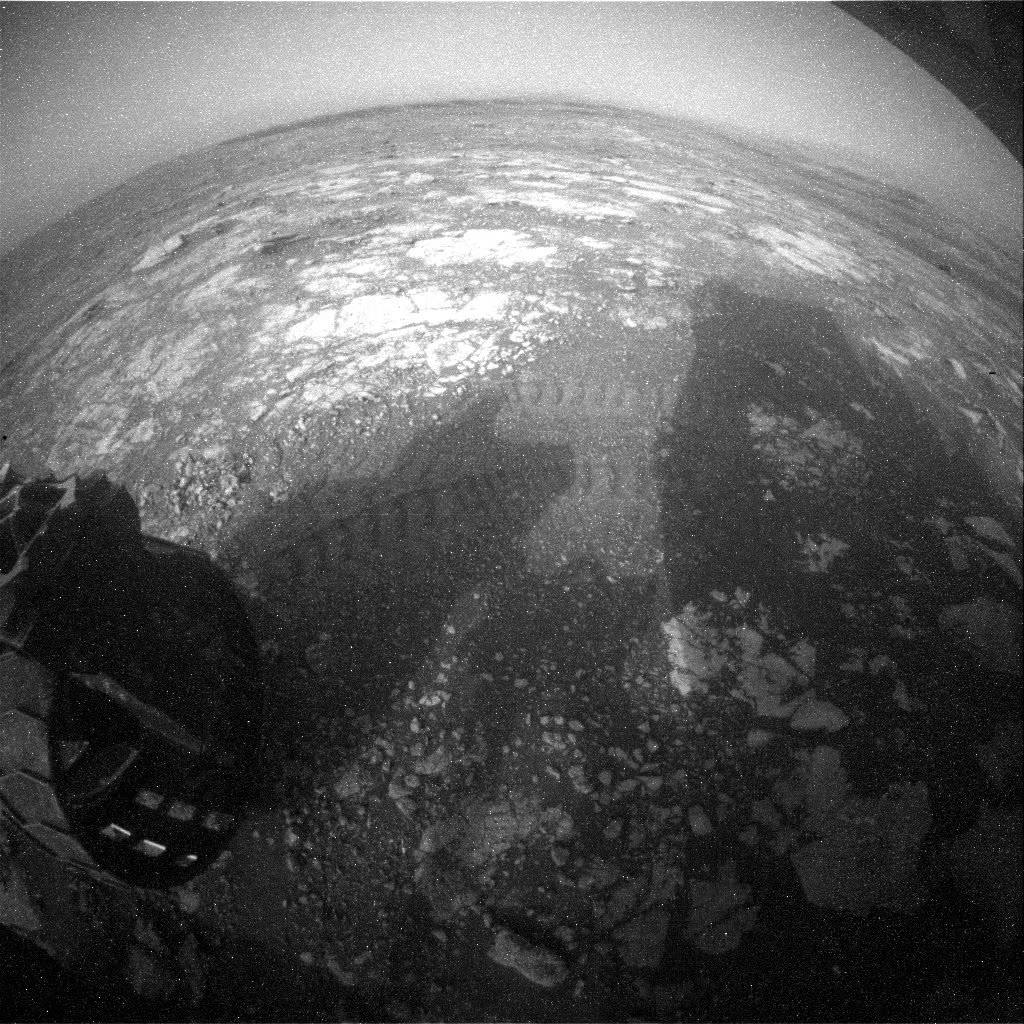

For this example, you picked a specific `earth_date (2020-07-01)` and then a specific photo from the response dictionary `(4)`. Before moving forward, try changing the date or fetching pictures from a different [camera](https://github.com/corincerami/mars-photo-api#cameras) to see how that changes the end result.

###OAuth: Getting Started

Another very common standard in API authentication is [OAuth](https://oauth.net/). You’ll learn only the essentials of OAuth in this tutorial since it’s a very broad topic.

Even if you weren’t aware that it was part of OAuth, you may have seen and used the OAuth flow multiple times. Every time an app or platform has a *Login With* or *Continue With* option, that’s the starting point of an OAuth flow:

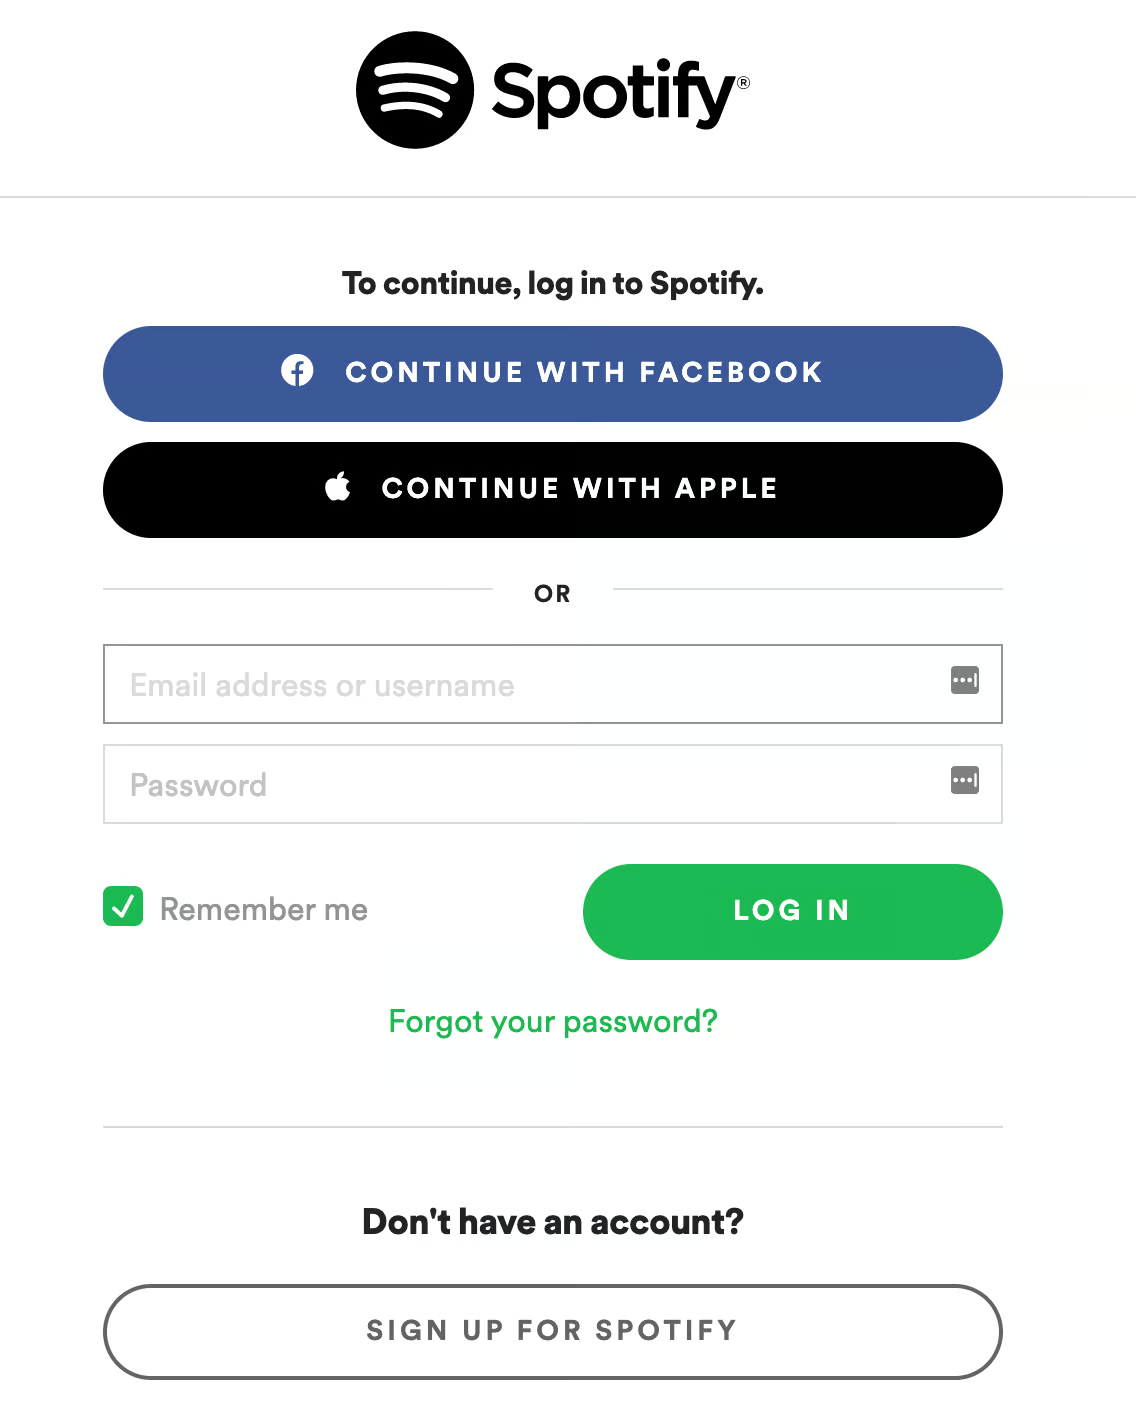

Here’s a step-by-step breakdown of what will happen if you click `Continue With Facebook`:

1. The Spotify app will ask the Facebook API to start an authentication flow. To do this, the Spotify app will send its application ID `(client_id)` and a URL `(redirect_uri)` to redirect the user after success or error.

2. You’ll be redirected to the Facebook website and asked to log in with your credentials. The Spotify app won’t see or have access to these credentials. *This is the most important benefit of OAuth*.

3. Facebook will show you all the data that the Spotify app is requesting from your profile and ask you to accept or reject sharing that data.

4. If you accept giving Spotify access to your data, then you’ll be redirected back to the Spotify app, already logged in.

When going through step 4, Facebook will provide Spotify with a special credential `(access_token)` that it can use repeatedly to fetch your information. This specific Facebook login token is valid for sixty days, but other apps might have different expiration periods. If you’re curious, then Facebook has a [settings page](https://www.facebook.com/settings?tab=applications&ref=settings) that you can check to see which apps have gotten your Facebook access token.

Now, from a more technical standpoint, here’s what you need to know when consuming APIs using OAuth:

*    You need to create an application that will have an ID `(app_id or client_id)` and a secret `(app_secret or client_secret)`.
*    You need to have a redirect URL `(redirect_uri)`, which the API will use to send information to you.
*    You’ll get a code as the result of the authentication, which you need to exchange for an access token.

There are a few variations to the above, but generally speaking, most OAuth flows will have steps similar to these.

* ! Tip: When you’re just testing things out and you need some sort of redirect URL to get a code, you can use a service called [httpbin](https://httpbin.org/).

More specifically, you can use https://httpbin.org/anything as a redirect URL, as it’ll simply output whatever it gets as an input. You can test it yourself by navigating to that URL.

Next, you’ll dive into an example using the GitHub API!

###OAuth: A Practical Example

As you saw above, the first step is to create an application. The [GitHub documentation](https://docs.github.com/en/apps/oauth-apps/building-oauth-apps/creating-an-oauth-app) offers a great step-by-step explanation that you can follow to do this. The only point to keep in mind is that you need to use the https://httpbin.org/anything URL mentioned above for the Authorization callback URL field.

* ! **GitHub API**: You can use the [GitHub API](https://docs.github.com/en/rest?apiVersion=2022-11-28) for a lot of different use cases, such as getting a list of repositories that you’re a part of, getting a list of your followers, and much more.

Once you’ve created your app, copy and paste the `Client_ID` and `Client_Secret`, together with your selected redirect URL, into a Python file called `github.py`:

In [ ]:
import requests

# REPLACE the following variables with your Client ID and Client Secret
CLIENT_ID = "Ov23li62Q0soLQxkyj3"
CLIENT_SECRET = "a9fc259a3074daf61be7d71cfa55a77437f3bd0"

# REPLACE the following variable with what you added in the
# "Authorization callback URL" field
REDIRECT_URI = "https://httpbin.org/anything"


Now that you have all the important variables in place, you need to be able to create a link to redirect the user to their GitHub account, as the [GitHub documentation](https://docs.github.com/en/apps/oauth-apps/building-oauth-apps/authorizing-oauth-apps#1-request-a-users-github-identity) explains:

In [ ]:
# ...

def create_oauth_link():
    params = {
        "client_id": CLIENT_ID,
        "redirect_uri": REDIRECT_URI,
        "scope": "user",
        "response_type": "code",
    }

    endpoint = "https://github.com/login/oauth/authorize"
    response = requests.get(endpoint, params=params)
    return response.url

In this piece of code, you first define the required parameters that the API expects and then call the API using the requests package and `.get()`.

When you make the request to the `/login/oauth/authorize` endpoint, the API will automatically redirect you to the GitHub website. In that case, you want to fetch the `url` parameter from the response. This parameter contains the exact URL that GitHub is redirecting you to.

The next step in the authorization flow is to exchange the code you get for an access token. Again, following the steps in [GitHub’s documentation](https://docs.github.com/en/apps/oauth-apps/building-oauth-apps/authorizing-oauth-apps#2-users-are-redirected-back-to-your-site-by-github), you can make a function for it:

In [ ]:
# ...

def exchange_code_for_access_token(code=None):
    params = {
        "client_id": CLIENT_ID,
        "client_secret": CLIENT_SECRET,
        "redirect_uri": REDIRECT_URI,
        "code": code,
    }

    headers = {"Accept": "application/json"}
    endpoint = "https://github.com/login/oauth/access_token"
    response = requests.post(endpoint, params=params, headers=headers).json()
    return response["access_token"]

Here, you make a `POST` request to exchange the code for an access token. In this request, you have to send your `CLIENT_SECRET` and code so that GitHub can validate that this specific code was initially generated by your application. Only then will the GitHub API generate a valid access token and return it to you.

Now you can add the following to your file and try running it:

In [ ]:
# ...

link = create_oauth_link()
print(f"Follow the link to start the authentication with GitHub: {link}")
code = input("GitHub code: ")
access_token = exchange_code_for_access_token(code)
print(f"Exchanged code {code} with access token: {access_token}")

If everything goes according to plan, then you should be rewarded with a valid access token that you can use to make calls to the GitHub API, impersonating the authenticated user.

Now try adding the following code to fetch your user profile using the [User API](https://docs.github.com/en/rest/users?apiVersion=2022-11-28#get-the-authenticated-user) and to print your name, username, and number of private repositories:

In [ ]:
# ...

def print_user_info(access_token=None):
    headers = {"Authorization": f"token {access_token}"}
    endpoint = "https://api.github.com/user"
    response = requests.get(endpoint, headers=headers).json()
    name = response["name"]
    username = response["login"]
    private_repos_count = response["total_private_repos"]
    print(
        f"{name} ({username}) | private repositories: {private_repos_count}"
    )

# ...

Now that you have a valid access token, you need to send it on all your API requests using the `Authorization` header. The response to your request will be a Python dictionary containing all the user information. From that dictionary, you want to fetch the fields `name`, `login`, and `total_private_repos`. You can also print the `response` variable to see what other fields are available.

All right, that should be it! The only step left to do is to put it all together and try it out:

In [ ]:
import requests

# REPLACE the following variables with your Client ID and Client Secret
CLIENT_ID = "Ov23li62Q0soLQxkyj3"
CLIENT_SECRET = "a9fc259a3074daf61be7d71cfa55a77437f3bd0"

# REPLACE the following variable with what you added in
# the "Authorization callback URL" field
REDIRECT_URI = "https://httpbin.org/anything"

def create_oauth_link():
    params = {
        "client_id": CLIENT_ID,
        "redirect_uri": REDIRECT_URI,
        "scope": "user",
        "response_type": "code",
    }
    endpoint = "https://github.com/login/oauth/authorize"
    response = requests.get(endpoint, params=params)
    return response.url

def exchange_code_for_access_token(code=None):
    params = {
        "client_id": CLIENT_ID,
        "client_secret": CLIENT_SECRET,
        "redirect_uri": REDIRECT_URI,
        "code": code,
    }
    headers = {"Accept": "application/json"}
    endpoint = "https://github.com/login/oauth/access_token"
    response = requests.post(endpoint, params=params, headers=headers).json()
    return response["access_token"]

def print_user_info(access_token=None):
    headers = {"Authorization": f"token {access_token}"}
    endpoint = "https://api.github.com/user"
    response = requests.get(endpoint, headers=headers).json()
    name = response["name"]
    username = response["login"]
    private_repos_count = response["total_private_repos"]
    print(
        f"{name} ({username}) | private repositories: {private_repos_count}"
    )

link = create_oauth_link()
print(f"Follow the link to start the authentication with GitHub: {link}")
code = input("GitHub code: ")
access_token = exchange_code_for_access_token(code)
print(f"Exchanged code {code} with access token: {access_token}")
print_user_info(access_token=access_token)

Follow the link to start the authentication with GitHub: https://github.com/login?client_id=Ov23li62Q0soLQxkyj38&return_to=%2Flogin%2Foauth%2Fauthorize%3Fclient_id%3DOv23li62Q0soLQxkyj38%26redirect_uri%3Dhttps%253A%252F%252Fhttpbin.org%252Fanything%26response_type%3Dcode%26scope%3Duser
GitHub code: b8d705fe45a34785864c
Exchanged code b8d705fe45a34785864c with access token: gho_REDACTED
None (anrom44444) | private repositories: 0


When you run the code above, you go through several steps. First, a link is generated asking you to go to a GitHub page for authentication.

After following that link and logging in with your GitHub credentials, you’re redirected to your defined callback URL with a code field in the query parameters:

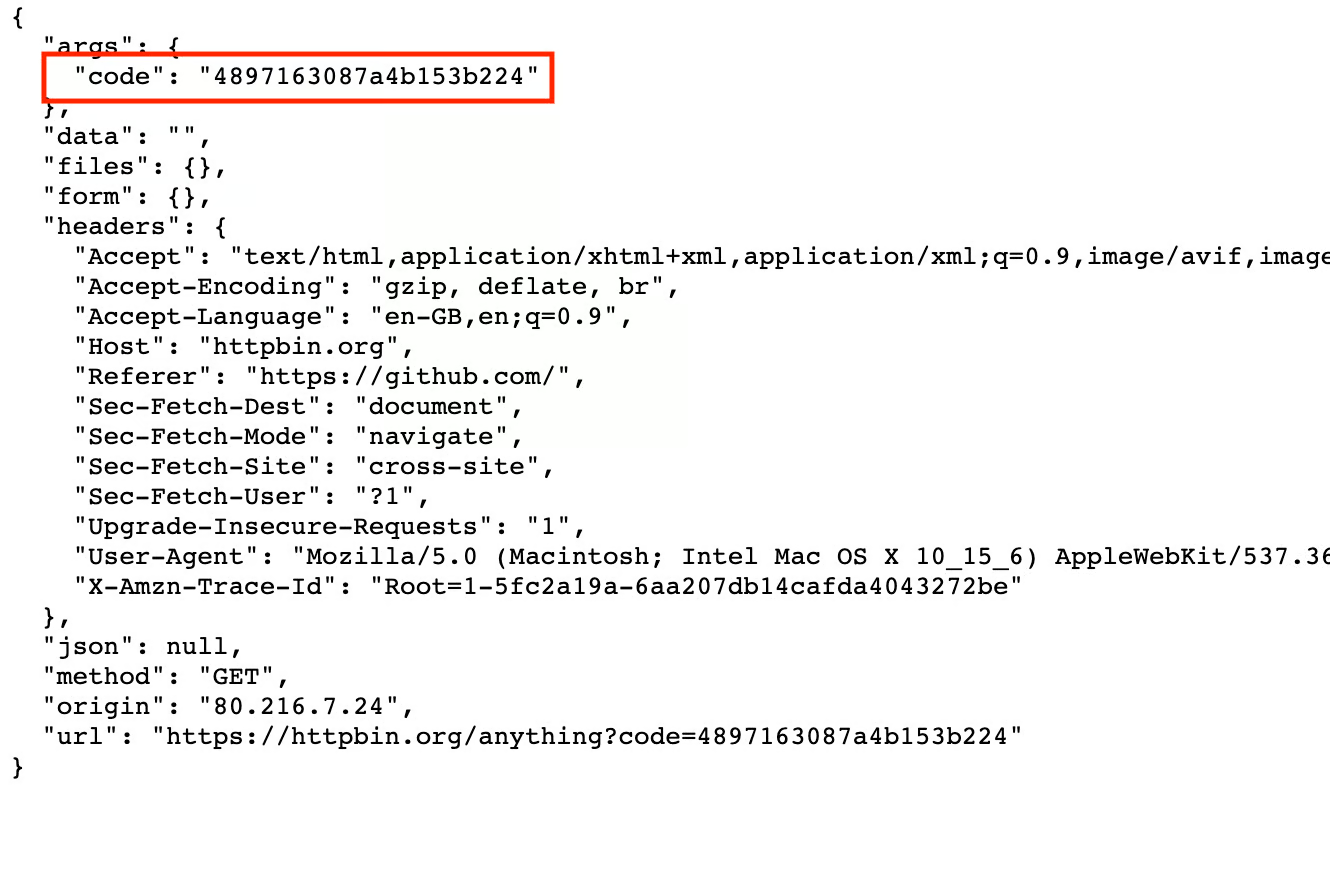

After pasting that code in your console, you exchange the code for a reusable access token.

Finally, the API fetches your user information with that access token. When you print your name, username, and number of private repositories, your result should look something like this:

*John Doe (johndoe) | number of private repositories: 42*

There are quite a few steps to take here, but it’s important that you take the time to really understand each one. Most APIs using OAuth will share a lot of the same behavior, so knowing this process well will unlock a lot of potential when you’re reading data from APIs.

Feel free to improve this example and add more functionality, such as getting your public and starred repositories or iterating through your followers to identify the most popular ones.

There are plenty of great resources online about OAuth, and if consuming APIs behind OAuth is what you really need, then you should do a bit more research on that topic specifically. Here are a few good places to start:

*    [What the Heck is OAuth?](https://developer.okta.com/blog/2017/06/21/what-the-heck-is-oauth)
*    [OAuth 2 Simplified](https://aaronparecki.com/oauth-2-simplified/)
*    [OAuth 2.0 Authorization Framework](https://auth0.com/docs/authenticate/protocols/oauth)

From an API consumption perspective, knowing OAuth will definitely come very in handy when you’re interacting with public APIs. Most APIs have adopted OAuth as their authentication standard, and with good reason.

###Pagination

Sending lots of data back and forth between clients and servers comes with a price: bandwidth. To make sure that servers can cope with a lot of requests, APIs typically use **pagination**.

In very simple terms, pagination is the act of splitting large amounts of data into multiple smaller pieces. For example, whenever you go to the [questions page](https://stackoverflow.com/questions) in Stack Overflow, you see something like this at the bottom:

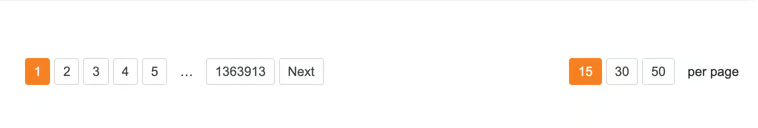

You probably recognize this from many other websites, and the concept is mostly the same across different sites. For APIs in particular, this is normally handled with the help of query parameters, mainly the following two:

1.    A page attribute that defines which page you’re currently requesting
2.    A size attribute that defines the size of each page

The specific query parameter names might vary a lot depending on the API developers, but the concept is the same. A few API players might also use HTTP headers or the JSON response to return current pagination filters in place.

Using the GitHub API again, you can find an [events](https://docs.github.com/en/rest/reference/activity#list-public-events) endpoint in the documentation that contains pagination query parameters. The parameter `per_page=` defines the number of items to return, and `page=` allows you to paginate through multiple results. Here’s how to use these parameters:

In [ ]:
response = requests.get("https://api.github.com/events?per_page=1&page=0")
response.json()[0]["id"]


'47100346095'

In [ ]:
response = requests.get("https://api.github.com/events?per_page=1&page=1")
response.json()[0]["id"]

'47100346937'

In [ ]:
response = requests.get("https://api.github.com/events?per_page=1&page=2")
response.json()[0]["id"]

With the [first URL](https://api.github.com/events?per_page=1&page=0), you’re only able to fetch one event. But using the `page=` query parameter, you can keep paginating through results, making sure that you’re able to fetch all of the events without overloading the API.

###Rate Limiting

Given that APIs are public facing, and anyone can use them, people with bad intentions often try to abuse them. To prevent such attacks, APIs use a technique called **rate limiting**, which restricts the number of requests that users can make in a given time frame.

Some APIs may actually block your IP or API keys if you go over the defined rate limit too often. Be careful not to exceed the limits set by the API developers. Otherwise, you might have to wait a while before calling that API again.

For the example below, you’ll once again use the GitHub API and the `/events` endpoint. According to its [documentation](https://docs.github.com/en/rest/using-the-rest-api/getting-started-with-the-rest-api?apiVersion=2022-11-28#rate-limiting), GitHub allows about sixty unauthenticated requests per hour. If you go above that, then you’ll get a `403` status code and won’t be able to make any more API calls for quite some time.

* ! **Warning**: Running the next piece of code will really block you from calling GitHub for some time, so make sure you don’t need access to GitHub’s API for a bit before you run it.

For the sake of demonstration, you’ll purposefully try to exceed GitHub’s rate limit to see what happens. In the code below, you’ll request data until you get a status code other than `200 OK`:

In [ ]:
endpoint = "https://api.github.com/events"
for i in range(1, 100):
    response = requests.get(endpoint)
    print(f"{i} - {response.status_code}")
    if response.status_code != 200:
        break

In [ ]:
response

In [ ]:
response.json()

There you have it: After about sixty requests, the API stopped returning `200 OK` responses and returned a `403 Forbidden` response instead, informing you that you exceeded the API rate limit.

Some APIs, like GitHub’s, might even include additional information in the headers regarding your current rate limit and the number of requests you have remaining. These are very helpful for you to avoid going over the defined limit. Have a look at the latest `response.headers` to see if you can find those specific rate-limiting headers.

##Consuming APIs With Python: Practical Examples

Now that you know all the theory and have experimented with a few APIs, you can consolidate your learning with some more practical examples. You can modify the examples below to tailor them to your own purposes.

###Searching and Fetching Trending GIFs

How about making a small script that fetches the top three trending GIFs from the [GIPHY](https://giphy.com/) website? To do this, you need to create an app and get an API key from GIPHY. You can find instructions by expanding the box below, and you can also check GIPHY’s [quickstart documentation](https://developers.giphy.com/docs/api/#quick-start-guide).

####Create a GIPHY App

#####Step 1: Create a GIPHY Account

You should start by creating a [GIPHY account](https://giphy.com/join):

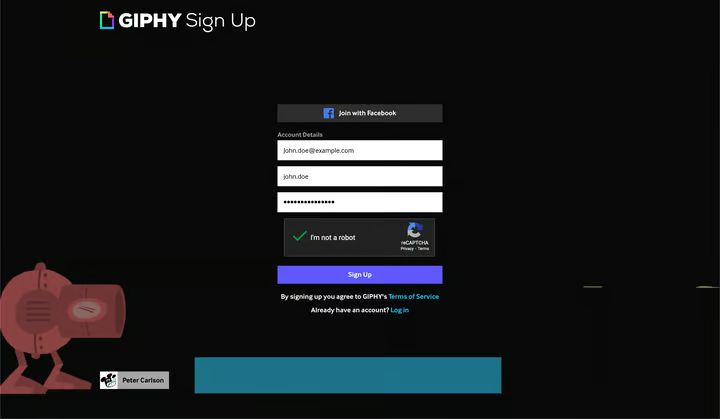

There’s nothing new here, just your typical email and password form, with an additional username field.

#####Step 2: Create an Application

After creating your GIPHY account, you can jump into the [Developer Dashboard](https://developers.giphy.com/dashboard/) to see your existing applications:

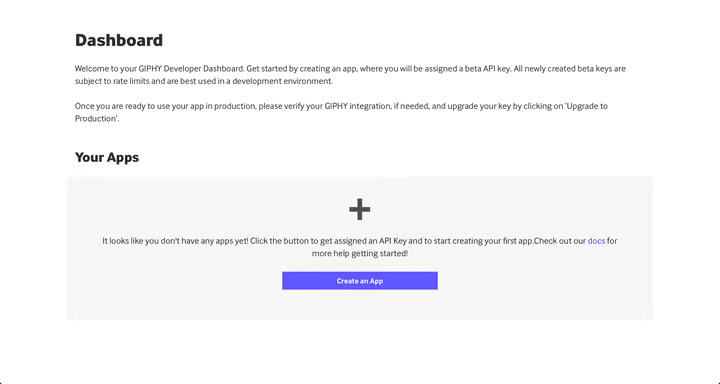

In this case, you haven’t set up an application yet, so it looks a bit empty. You can create your first application by clicking [Create an App](https://developers.giphy.com/dashboard/?create=true):

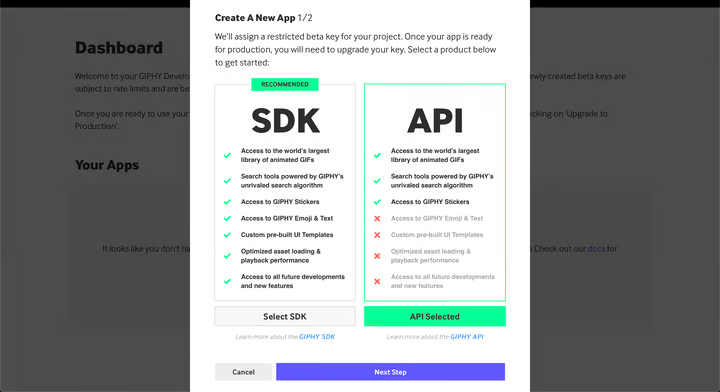

Make sure to select the API version, not the SDK one. After that, you’ll need to fill in a few more details about your application:

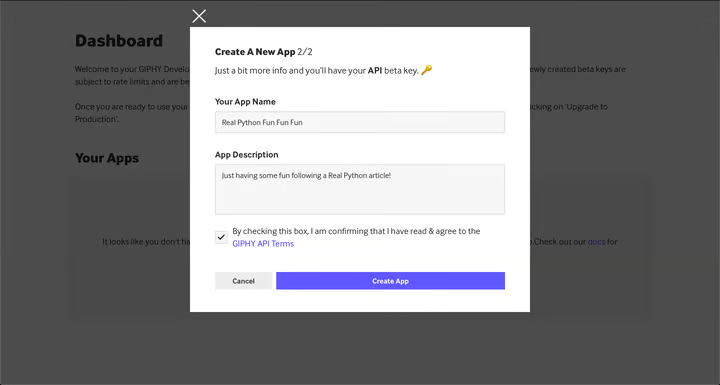

You can see an example application name and description above, but feel free to fill these out as you prefer.

#####Step 3: Fetching the API Key

Once you’ve completed the steps above, you should get a new app in your Dashboard, below the Your Apps section. In there, you’ll have an API key like so:

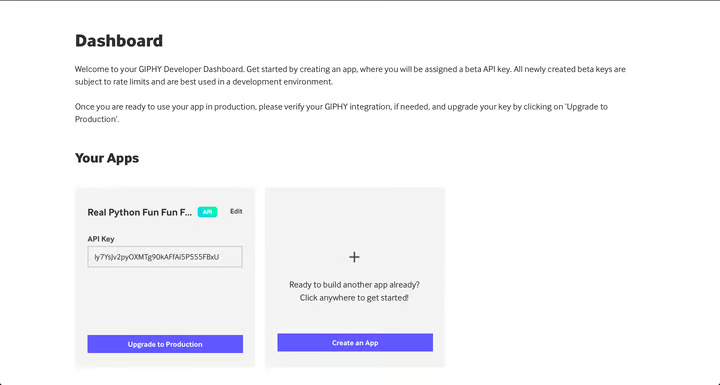

After you have the API key in your hands, you can start writing some code to consume this API. However, sometimes it’s a very good idea to run some tests before you implement a lot of code. A few APIs will actually provide you with tools to fetch API data directly from the documentation or their dashboard.

In this particular case, GIPHY provides you with an [API Explorer](https://developers.giphy.com/explorer/) that, after you create your app, allows you to start consuming the API without writing a line of code. Some other APIs will provide you with explorers within the documentation itself.

In any case, you can always use code to consume APIs, and that’s what you’ll do here. Grab the API key from the dashboard and, by replacing the value of the `API_KEY` variable below, you can start consuming the `GIPHY API`:

In [ ]:
# giphy_trending.py

import requests

# Replace the following with the API key generated.
API_KEY = "API_KEY"
endpoint = "https://api.giphy.com/v1/gifs/trending"

params = {"api_key": API_KEY, "limit": 3, "rating": "g"}
response = requests.get(endpoint, params=params).json()
for gif in response["data"]:
    title = gif["title"]
    trending_date = gif["trending_datetime"]
    url = gif["url"]
    print(f"{title} | {trending_date}\n{url}\n")

Let Me In Conan Obrien GIF by Team Coco | 2025-03-03 05:54:01
https://giphy.com/gifs/conan-obrien-3o6gb3kkXfLvdKEZs4

Good Night 90S GIF by Frankie | 0000-00-00 00:00:00
https://giphy.com/gifs/90s-fgfgif-r4BmI9xUaDuKJQdd3l

Mikey Madison GIF by NEON | 2025-03-03 03:39:48
https://giphy.com/gifs/neonrated-anora-movie-film-lK9f8c76eJiv82SDkp



In [ ]:
response

{'data': [], 'meta': {'status': 401, 'msg': 'Unauthorized', 'response_id': ''}}

At the top of the file, on lines 4 and 5, you define your `API_KEY` and the `GIPHY API` `endpoint` since they won’t change as often as the rest.

On line 7, making use of what you learned in the query parameters section, you define the `params` and add your own API key. You also include a couple of other filters: `limit` to get 3 results and rating to get only [appropriate content](https://developers.giphy.com/docs/optional-settings/#rating).

Finally, after getting a response, you iterate through the results on line 9. For each GIF, you print its title, date, and URL on line 13.

Running this piece of code in the console would output a somewhat structured list of GIFs:

In [ ]:
# Shell

$ python giphy_trending.py
Excited Schitts Creek GIF by CBC | 2024-11-28 20:45:14
https://giphy.com/gifs/cbc-schittscreek-schitts-creek-SiGg4zSmwmbafTYwpj

Saved By The Bell Shrug GIF by PeacockTV | 2024-11-28 20:30:15
https://giphy.com/gifs/peacocktv-saved-by-the-bell-bayside-high-school-dZRjehRpivtJsNUxW9

Schitts Creek Thank You GIF by CBC | 2024-11-28 20:15:07
https://giphy.com/gifs/cbc-funny-comedy-26n79l9afmfm1POjC

Now, say you want to make a script that allows you to search for a specific word and fetch the first GIPHY match for that word. A different endpoint and slight variation of the code above can do that quite quickly:

In [ ]:
# giphy_search.py

import requests

# Replace the following with the API key generated.
API_KEY = "API_KEY"
endpoint = "https://api.giphy.com/v1/gifs/search"

search_term = "shrug"
params = {"api_key": API_KEY, "limit": 1, "q": search_term, "rating": "g"}
response = requests.get(endpoint, params=params).json()
for gif in response["data"]:
    title = gif["title"]
    url = gif["url"]
    print(f"{title} | {url}")

Make It Stop My Brain Hurts GIF by Monty Python | https://giphy.com/gifs/edition-python-monty-tZ6zAdNZbWOhq


There you have it! Now you can modify this script to your liking and generate GIFs on demand. Try fetching GIFs from your favorite show or movie, adding a shortcut to your terminal to get the most popular GIFs on demand, or integrating with another API from your favorite messaging system—WhatsApp, Slack, you name it. Then start sending GIFs to your friends and coworkers!

####Searching Google Books

If you have a passion for books, then you might want a quick way to search for a specific book. You might even want to connect it to your local library’s search to see if a given book is available using the book’s [ISBN](https://en.wikipedia.org/wiki/ISBN).

For this example, you’ll use the Google [Books API](https://developers.google.com/books) and the public [volumes endpoint](https://developers.google.com/books/docs/v1/using#WorkingVolumes) to search for books.

Here’s a straightforward piece of code to look for the words `"moby dick"` in the whole catalog:

In [ ]:
# google_books.py

import requests

endpoint = "https://www.googleapis.com/books/v1/volumes"
query = "moby dick"

params = {"q": query, "maxResults": 7}
response = requests.get(endpoint, params=params).json()
for book in response["items"]:
    volume = book["volumeInfo"]
    title = volume.get("title", "")
    published = volume.get("publishedDate", "")
    description = volume.get("description", "")
    print(f"{title} ({published})\n{description}\n")

Moby-Dick (2002-12-31)
Herman Melville’s masterpiece of obsession and the untamed sea, one of the greatest works of imagination in literary history—featuring an introduction by Andrew Delbanco and notes by Tom Quirk. This edition features the Northwestern-Newberry edition of Melville's text, approved by the Center for Scholarly Editions and the Center for Editions of American Authors of the MLA. Nominated as one of America’s best-loved novels by PBS’s The Great American Read Moby-Dick still stands as an indisputable literary classic. It is the story of an eerily compelling madman pursuing an unholy war against a creature as vast and dangerous and unknowable as the sea itself. But more than just a novel of adventure, more than an encyclopedia of whaling lore and legend, Moby-Dick is a haunting, mesmerizing, and important social commentary populated with several of the most unforgettable and enduring characters in literature. Written with wonderfully redemptive humor, Moby-Dick is a prof

This code example is pretty similar to the ones you’ve seen before. You start on lines 3 and 4 by defining important variables, such as the endpoint and, in this case, the query.

After making the API request, on line 8 you start iterating through the results. Then, on line 13, you print the most interesting information for each book that matches your initial query:

In [ ]:
# Shell

$ python google_books.py
Moby-Dick (2016-04-12)
"Call me Ishmael." So begins the famous opening...

Moby Dick (1892)
A literary classic that wasn't recognized for its...

Moby Dick; Or, The Whale (1983-08-16)
The story of Captain Ahab's...

You can print the book variable inside the loop to see what other fields you have available. Here are a few that could be useful for further improving this code:

*    `industryIdentifiers`
*    `averageRating and ratingsCount`
*    `imageLinks`

A fun challenge to do with this API is to use your [OAuth knowledge](https://developers.google.com/books/docs/v1/using#auth) and create your own bookshelf app that keeps records of all the books that you’ve read or want to read. You can even connect it to your favorite bookstore or library afterward to quickly find books from your wish list that are available near you. This is just one idea. Can you come up with more?

##API hubs

https://apidog.com/articles/5-best-api-hubs/

[rapidapi.com](rapidapi.com), the world's largest API hub, is used by over five million developers to find, test, and connect to thousands of APIs — all with a single API key. We call these developers that call existing APIs API consumers.

[API Hub](https://apidog.com/apihub/) is an open API interface sharing platform under Apidog, providing a massive collection of APIs and documentation. Developers can easily search, use, and share API interfaces on this platform.

[Twilio](https://www.twilio.com/) is a cloud communications platform that offers various APIs for services like SMS, voice calls, video, and more. Twilio provides SDKs for different programming languages and platforms, making it user-friendly and enhancing the development experience. It also offers comprehensive documentation and examples to facilitate quick integration.

##AI API

https://www.tavus.io/post/ai-apis

An AI API, or artificial intelligence application programming interface, is a type of technology that allows developers to incorporate artificial intelligence features into applications. These APIs serve as bridges that connect AI functionalities with various applications, enabling them to perform complex tasks such as facial recognition, spam filtering, and sentiment analysis more efficiently.

In simpler terms, AI APIs provide access to pre-trained machine learning models which can be integrated into existing systems to make applications smarter and more capable without the need for extensive AI expertise from the user.

##Conclusion

There’s so much you can learn about APIs: different headers, different content types, different authentication techniques, and so on. However, the concepts and techniques that you’ve learned in this tutorial will allow you to practice with any API you like and to use Python for any API consumption needs you may have.

**In this tutorial**, **you’ve learned**:

*    What an **API** is and what you can use it for
*    What **status codes**, **HTTP headers**, and **HTTP methods** are
*    How you can use Python to **consume public data** using APIs
*    How you can use **authentication** when consuming APIs with Python


## Check Your Understanding

In [12]:
import requests
import ipywidgets as widgets
from IPython.display import display, clear_output, FileLink
import json

**Task 1**. Find a photo from Mars that was taken on your birthday (Mars Rover Photo API).

In [7]:
def get_mars_photo_on_birthday(birthday_mm_dd, start_year=2012, end_year=2025):
    api_key = "DEMO_KEY"
    endpoint = "https://api.nasa.gov/mars-photos/api/v1/rovers/curiosity/photos"
    for year in range(start_year, end_year + 1):
        earth_date = f"{year}-{birthday_mm_dd}"
        params = {"earth_date": earth_date, "api_key": api_key}
        response = requests.get(endpoint, params=params)
        if response.status_code != 200:
            continue
        data = response.json()
        if data.get("photos"):
            return data["photos"][0]["img_src"], earth_date
    return None, None

def on_button_clicked(b):
    clear_output()
    display(birthday_input, button)
    birthday = birthday_input.value
    photo_url, photo_date = get_mars_photo_on_birthday(birthday)
    if photo_url:
        print(f"\nMars photo taken on {photo_date}:")
        print(photo_url)
    else:
        print("No Mars photos found for your birthday in the selected year range.")

birthday_input = widgets.Text(value='11-30', description='Birthday (MM-DD):')
button = widgets.Button(description="Get Photo")
button.on_click(on_button_clicked)
display(birthday_input, button)

Text(value='11-30', description='Birthday (MM-DD):')

Button(description='Get Photo', style=ButtonStyle())

**Task 2**. Choose one of the API Categories on rapidapi.com, find one API that offers multiple endpoints, and add examples of getting data from these endpoints to your colab notebook.

In [10]:
RAPIDAPI_KEY = "DEMO_KEY"
RAPIDAPI_HOST = "coingecko.p.rapidapi.com"
headers = {
    "X-RapidAPI-Key": RAPIDAPI_KEY,
    "X-RapidAPI-Host": RAPIDAPI_HOST
}

def get_market_data():
    url = f"https://{RAPIDAPI_HOST}/coins/markets"
    querystring = {"vs_currency": "usd", "order": "market_cap_desc", "per_page": "5", "page": "1"}
    response = requests.get(url, headers=headers, params=querystring)
    return response.json()

def get_coin_details(coin_id):
    url = f"https://{RAPIDAPI_HOST}/coins/{coin_id}"
    response = requests.get(url, headers=headers)
    return response.json()

def get_historical_data(coin_id, date):
    url = f"https://{RAPIDAPI_HOST}/coins/{coin_id}/history"
    querystring = {"date": date}
    response = requests.get(url, headers=headers, params=querystring)
    return response.json()

def on_market_clicked(b):
    clear_output()
    display(coin_input, date_input, market_button, details_button, historical_button)
    md = get_market_data()
    print("Market Data:\n", json.dumps(md, indent=2))

def on_details_clicked(b):
    clear_output()
    display(coin_input, date_input, market_button, details_button, historical_button)
    cd = get_coin_details(coin_input.value)
    print("Coin Details:\n", json.dumps(cd, indent=2))

def on_historical_clicked(b):
    clear_output()
    display(coin_input, date_input, market_button, details_button, historical_button)
    hd = get_historical_data(coin_input.value, date_input.value)
    print("Historical Data:\n", json.dumps(hd, indent=2))

coin_input = widgets.Text(value="bitcoin", description="Coin ID:")
date_input = widgets.Text(value="30-12-2023", description="Date (DD-MM-YYYY):")
market_button = widgets.Button(description="Market Data")
details_button = widgets.Button(description="Coin Details")
historical_button = widgets.Button(description="Historical Data")

market_button.on_click(on_market_clicked)
details_button.on_click(on_details_clicked)
historical_button.on_click(on_historical_clicked)

display(coin_input, date_input, market_button, details_button, historical_button)

Text(value='bitcoin', description='Coin ID:')

Text(value='30-12-2023', description='Date (DD-MM-YYYY):')

Button(description='Market Data', style=ButtonStyle())

Button(description='Coin Details', style=ButtonStyle())

Button(description='Historical Data', style=ButtonStyle())

**Task 3**. Tracxn is one of the largest platforms for tracking start-ups and private companies. [Tracxn Playground API](https://platform.tracxn.com/a/api/playground/about) is a free and fully-featured environment that allows you to safely test prototypes and integrations. Tracxn's Playground API is currently supports the following APIs with support for more in the pipeline: Companies API, Transactions API, Investors API, Acquisitions API, Practice Area API, Feed API, Business Model API.


The [Companies API](https://platform.tracxn.com/a/api/documentation/companies) allows you to query the Company Database and apply multiple filters and sorts.

In [ ]:
import requests

requestUrl = "https://platform.tracxn.com/api/2.2/playground/companies"
accessToken = "accessToken"
requestBody = {
    "filter":{
        "feedName":[
            "Cybersecurity"
            ],
        "city":[
            "San Francisco"
        ],
        "foundedYear": [
            "2018",
            "2017",
            "2016"
        ]
    }
}

res = requests.post(requestUrl, headers={'accessToken': accessToken}, json=requestBody)

In [ ]:
res

<Response [200]>

In [ ]:
res.json()

The [Investors API](https://platform.tracxn.com/a/api/documentation/investors) allows you to query the Investor database for all type of investors, and apply multiple filters and sorts

In [ ]:
import requests

requestUrl = "https://platform.tracxn.com/api/2.2/playground/investors"
accessToken = "ec675156-fdfc-49a0-898e-ac39bfcc94"
requestBody = {
        "filter": {
        "investorCountry": [
            "Germany"
        ]
    }
}

res = requests.post(requestUrl, headers={'accessToken': accessToken}, json=requestBody)

In [ ]:
res.json()

{'result': [{'locations': [{'city': {'name': 'Munich',
      'tracxnId': 'EO3e1kDttkGWc_T_m6Wg0fZDUjC6nnWdtmuiP3_lQZc'},
     'state': {'name': 'Bavaria',
      'tracxnId': 'K0ma575PgTiWNni_bxhgrfpgtKYRIPwsnVqncMY40Z4'},
     'country': {'name': 'Germany',
      'tracxnId': 'K0ma575PgTiWNni_bxhgrecqamCJHL5gYUjUxBJlRqA'},
     'continent': {'name': 'Europe',
      'tracxnId': 'qxtonp3KBK2rERVv1-oXjXxoGMFM7GirB7RZoEtwnQM'},
     'countryGroup': [{'name': 'Europe',
       'tracxnId': 'Dq0oWnD6PF5ncRTno-dqhbSHAuad0ODAShwTHUPYDTc'},
      {'name': 'DACH',
       'tracxnId': 'CNPaMsIM_8uD9Xm1kiyhgcDlMnrmVEm0fcgU88T9_s0'},
      {'name': 'Western Europe',
       'tracxnId': 'MBeJu89NTBl9ndjSEFH8QdIiu3Ku99TM5zBIAMkuMuM'},
      {'name': 'Euro',
       'tracxnId': '3hxiB8ywiwFG-1njShcw_V7ps2Baoim9VcgbvS57UTk'}]}],
   'businessModelList': [{'description': 'Companies with investment funds focused on making equity investments in startups across various sectors and investment stages',
     'name': 

Create a class to represent the **Investor**. Basic information to be provided: full information about the investor
Main implemented behavior: access to the domain name and adding or change domain name

Output in files poland_json.txt, ukraine_json.txt, germany_json.txt

In [14]:
API_KEY = "DEMO_KEY"
BASE_URL = "https://platform.tracxn.com/api/investors"
headers = {"Authorization": f"Bearer {API_KEY}"}

def get_investor_by_country(country):
    params = {"country": country, "limit": 1}
    response = requests.get(BASE_URL, headers=headers, params=params)
    if response.status_code == 200:
        data = response.json()
        if "investors" in data and data["investors"]:
            return data["investors"][0]
    return None

class Investor:
    def __init__(self, data):
        self.data = data
    @property
    def domain(self):
        return self.data.get("domain")
    @domain.setter
    def domain(self, new_domain):
        self.data["domain"] = new_domain
    def full_info(self):
        return self.data

data_poland = get_investor_by_country("Poland") or {
    "name": "Investor Poland",
    "country": "Poland",
    "domain": "poland-investments.pl",
    "other_info": "Default investor data for Poland"
}
data_ukraine = get_investor_by_country("Ukraine") or {
    "name": "Investor Ukraine",
    "country": "Ukraine",
    "domain": "ukraine-investments.ua",
    "other_info": "Default investor data for Ukraine"
}
data_germany = get_investor_by_country("Germany") or {
    "name": "Investor Germany",
    "country": "Germany",
    "domain": "germany-investments.de",
    "other_info": "Default investor data for Germany"
}

investor_poland = Investor(data_poland)
investor_ukraine = Investor(data_ukraine)
investor_germany = Investor(data_germany)

with open("poland_json.txt", "w") as f:
    json.dump(investor_poland.full_info(), f, indent=2)
with open("ukraine_json.txt", "w") as f:
    json.dump(investor_ukraine.full_info(), f, indent=2)
with open("germany_json.txt", "w") as f:
    json.dump(investor_germany.full_info(), f, indent=2)

display(FileLink("poland_json.txt"))
display(FileLink("ukraine_json.txt"))
display(FileLink("germany_json.txt"))

C:\Users\partu\Desktop\mykhailyshchuk_op_2\week_7\poland_json.txt

C:\Users\partu\Desktop\mykhailyshchuk_op_2\week_7\ukraine_json.txt

C:\Users\partu\Desktop\mykhailyshchuk_op_2\week_7\germany_json.txt

Output Keys for response json

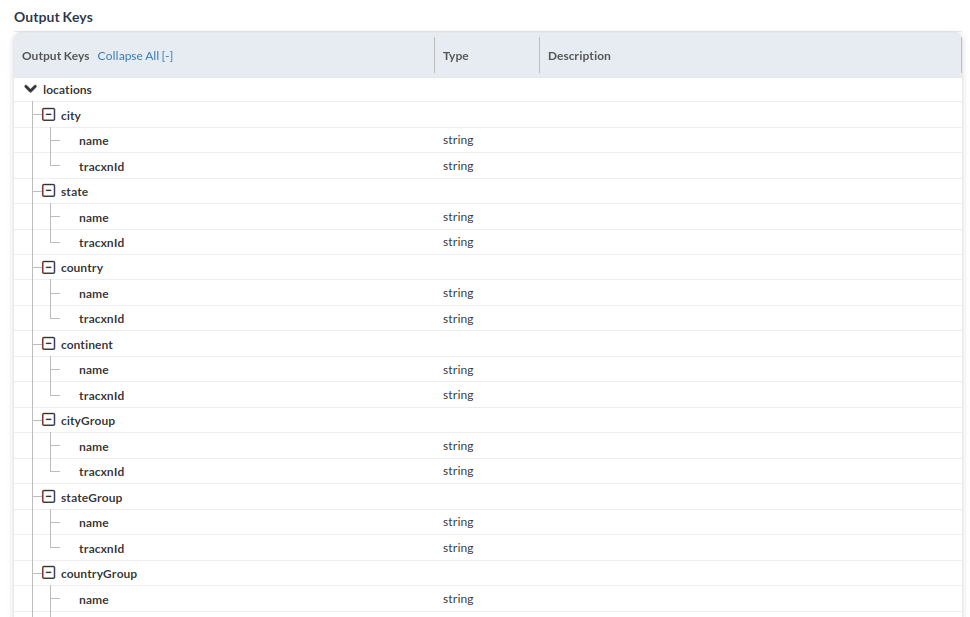

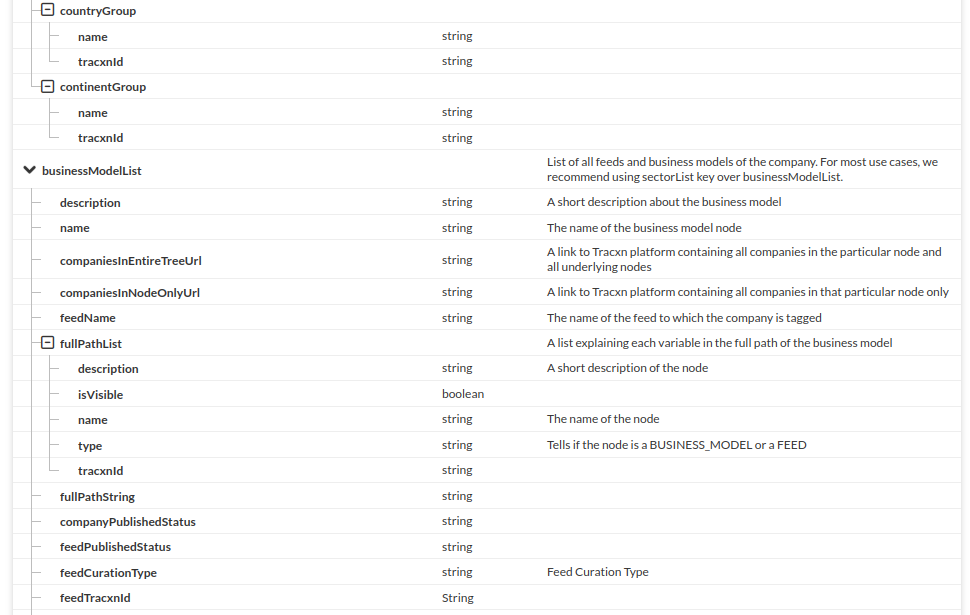

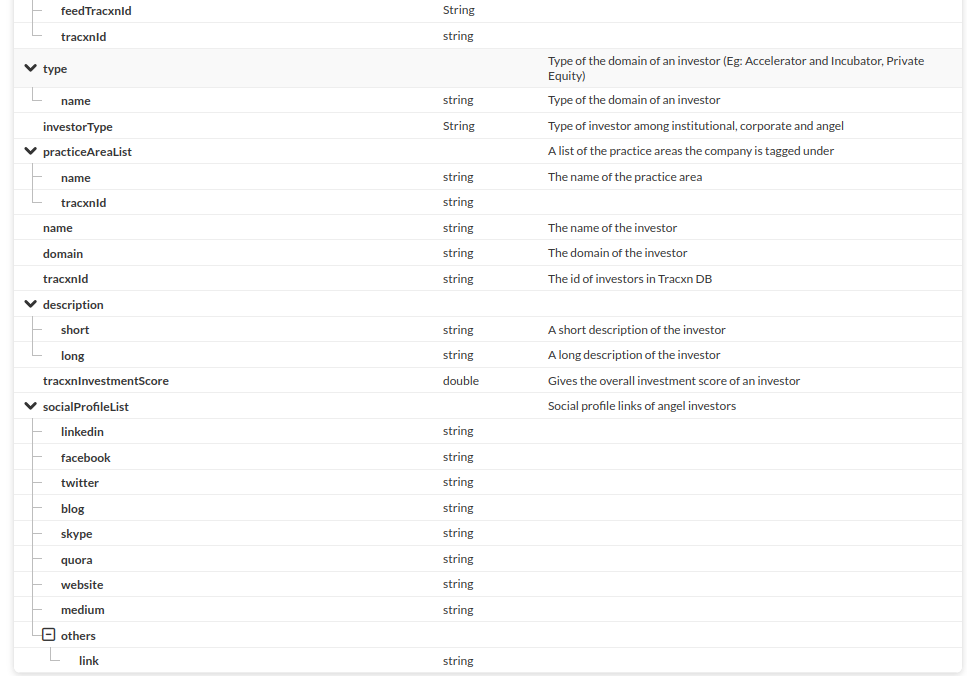